# PRCP-1020: House Price Prediction

**Project level:** Intermediate student project  
**Goal:** Use house details to estimate sale prices and explore which features are related to price.

The supplied data is the Ames, Iowa housing dataset. The target is `SalePrice`. There is no separate `test.csv`, so this project splits the supplied file into training and test data. Keep `data.csv` in the same folder as this notebook. The notebook calculates all results when run; no model scores are filled in ahead of time.


## 1. Importing Libraries

We will inspect the data, handle missing values, make a few simple charts, prepare the features, compare regression models with cross-validation, tune one model, and report its test-set results. The test set is kept aside during model selection. This gives a fair estimate for similar Ames homes, but it does not guarantee performance in another city or in today's market.


In [24]:
# Main packages used in this project: pandas, numpy, matplotlib, seaborn, and scikit-learn
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')


## 2. Dataset Loading

In [45]:
df = pd.read_csv(r"C:\Users\asdee\OneDrive\Desktop\House Price\data.csv")
display(df.head())


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Understand the data

Each row represents one house sale. `SalePrice` is the value we want to predict. `Id` only identifies a row, so it will not be used as a model feature.

In [26]:
print('Rows:', len(df))
print('Columns:', len(df.columns))
print('Duplicate rows:', df.duplicated().sum())
print('Missing SalePrice values:', df['SalePrice'].isna().sum())
print('Column data types:')
display(df.dtypes.value_counts().rename_axis('data type').to_frame('number of columns'))
display(df['SalePrice'].describe().to_frame('SalePrice (USD)'))


Rows: 1460
Columns: 81
Duplicate rows: 0
Missing SalePrice values: 0
Column data types:


,number of columns
data type,
str,43
int64,35
float64,3


,SalePrice (USD)
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


In [27]:
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame('missing values'))


,missing values
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageFinish,81
GarageType,81


## 4. Clean missing values

The Ames data guide uses blank entries for features a home does not have. For example, a blank pool or garage description means there is no pool or garage. We mark those text values as `None`, and use zero for the matching size or year fields. Other missing values, such as an unknown street frontage, stay missing and will be filled by the model's imputer using training data only.


In [28]:
data = df.drop_duplicates().copy()

# Blank descriptions that mean the house does not have that feature.
no_feature_columns = [
    'Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'PoolQC', 'Fence', 'MiscFeature'
]
for column in no_feature_columns:
    if column in data.columns:
        data[column] = data[column].fillna('None')

# Treat blank veneer type as no veneer if its measured area is zero or missing.
if 'MasVnrArea' in data.columns and 'MasVnrType' in data.columns:
    no_veneer = data['MasVnrArea'].fillna(0).eq(0)
    data.loc[no_veneer, 'MasVnrArea'] = 0
    data.loc[no_veneer & data['MasVnrType'].isna(), 'MasVnrType'] = 'None'

# Missing sizes/years are zero only when the corresponding feature is absent.
for column in ['GarageYrBlt', 'GarageCars', 'GarageArea']:
    if column in data.columns and 'GarageType' in data.columns:
        data.loc[data[column].isna() & data['GarageType'].eq('None'), column] = 0
for column in ['BsmtFinSF1','BsmtFinSF2','BsmtUnfSF','TotalBsmtSF','BsmtFullBath','BsmtHalfBath']:
    if column in data.columns:
        no_basement = data['BsmtQual'].eq('None') if 'BsmtQual' in data.columns else False
        data.loc[data[column].isna() & no_basement, column] = 0

print('Remaining missing values (these are unknown and will be imputed):')
remaining = data.isna().sum()
display(remaining[remaining > 0].to_frame('unknown values'))


Remaining missing values (these are unknown and will be imputed):


,unknown values
LotFrontage,259
MasVnrType,5
Electrical,1


## 5. Explore the data

The charts give a quick view of prices, feature relationships, and group differences. The notes below each chart are generated from the dataset when the notebook runs. They describe patterns and do not prove cause and effect.


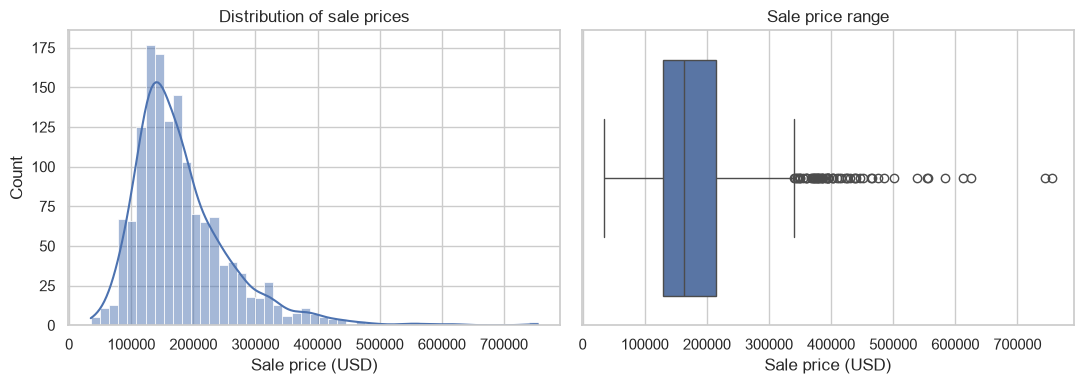

Interpretation: Average price is $180,921; median price is $163,000. Skewness is 1.88. A long upper tail means a small number of homes sold for much more than most homes.


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('Distribution of sale prices')
axes[0].set_xlabel('Sale price (USD)')
sns.boxplot(x=data['SalePrice'], ax=axes[1])
axes[1].set_title('Sale price range')
axes[1].set_xlabel('Sale price (USD)')
plt.tight_layout()
plt.show()
print(f"Interpretation: Average price is ${data.SalePrice.mean():,.0f}; median price is ${data.SalePrice.median():,.0f}. Skewness is {data.SalePrice.skew():.2f}. A long upper tail means a small number of homes sold for much more than most homes.")


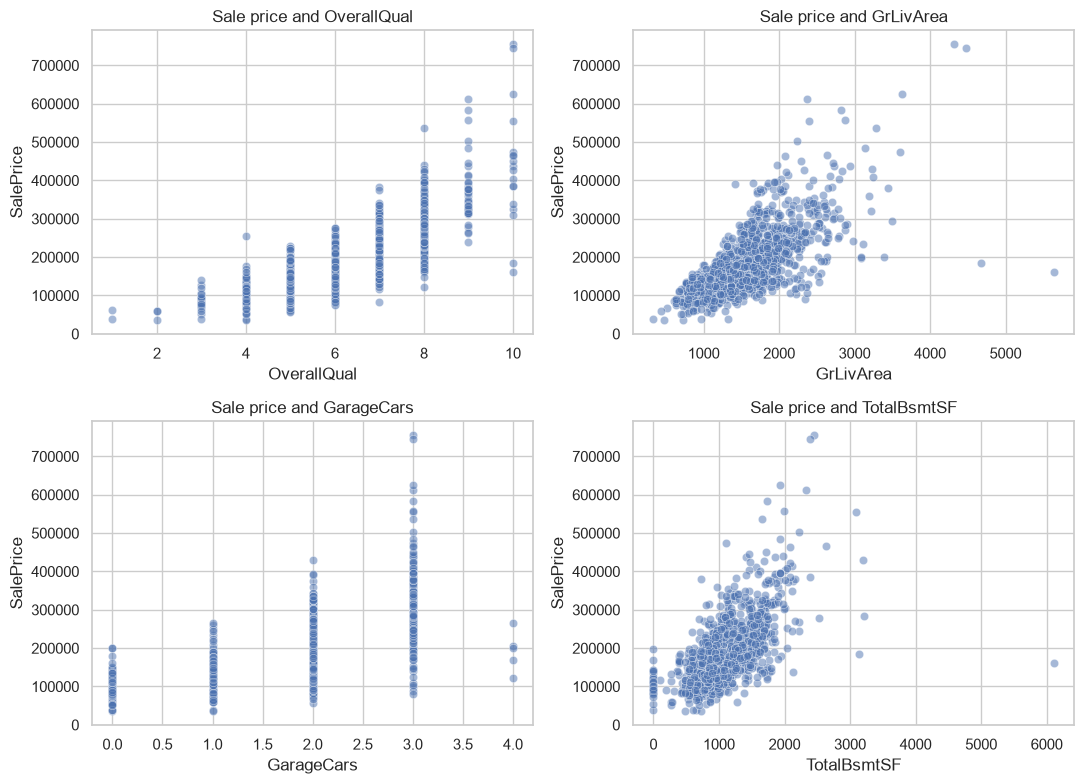

Interpretation: The charts compare price with quality, living area, garage size, and basement size. Correlations in this sample are:


,correlation with SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
TotalBsmtSF,0.613581


A positive correlation means higher values tend to occur with higher prices in this dataset. It does not mean the feature alone causes a higher price.


In [30]:
features_to_plot = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF']
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, column in zip(axes.flat, features_to_plot):
    sns.scatterplot(data=data, x=column, y='SalePrice', alpha=.5, ax=ax)
    ax.set_title(f'Sale price and {column}')
plt.tight_layout()
plt.show()
correlations = data[features_to_plot + ['SalePrice']].corr(numeric_only=True)['SalePrice'].drop('SalePrice').sort_values(ascending=False)
print('Interpretation: The charts compare price with quality, living area, garage size, and basement size. Correlations in this sample are:')
display(correlations.to_frame('correlation with SalePrice'))
print('A positive correlation means higher values tend to occur with higher prices in this dataset. It does not mean the feature alone causes a higher price.')


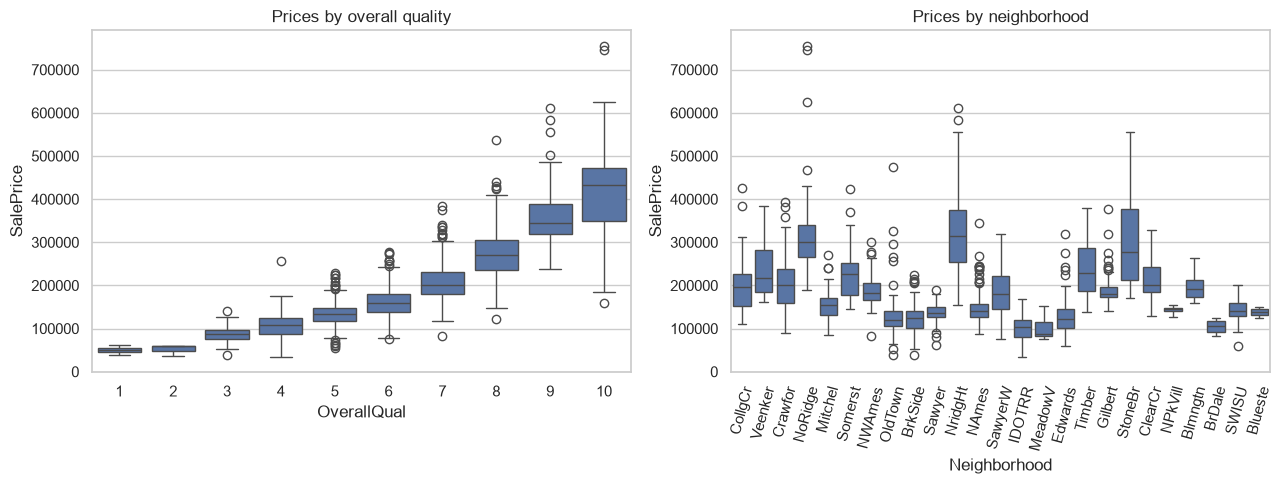

Interpretation: Median price by quality ranges from $50,150 to $432,390. Neighborhood medians range from $88,000 to $315,000. Group differences may also reflect size, age, and other home features.


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=data, x='OverallQual', y='SalePrice', ax=axes[0])
axes[0].set_title('Prices by overall quality')
sns.boxplot(data=data, x='Neighborhood', y='SalePrice', ax=axes[1])
axes[1].tick_params(axis='x', rotation=75)
axes[1].set_title('Prices by neighborhood')
plt.tight_layout()
plt.show()
quality_median = data.groupby('OverallQual')['SalePrice'].median()
hood_median = data.groupby('Neighborhood')['SalePrice'].median()
print(f"Interpretation: Median price by quality ranges from ${quality_median.min():,.0f} to ${quality_median.max():,.0f}. Neighborhood medians range from ${hood_median.min():,.0f} to ${hood_median.max():,.0f}. Group differences may also reflect size, age, and other home features.")


## 6. Check unusual values

The interquartile range (IQR) rule flags very small or large values for review. A flag does not automatically mean a mistake, so we keep all homes in this project unless we find a data-entry problem.

In [32]:
check_columns = ['SalePrice','LotArea','GrLivArea','TotalBsmtSF']
summary = []
for column in check_columns:
    q1 = data[column].quantile(.25)
    q3 = data[column].quantile(.75)
    iqr = q3 - q1
    high_count = ((data[column] < q1 - 1.5*iqr) | (data[column] > q3 + 1.5*iqr)).sum()
    summary.append({'feature':column, 'possible outliers':int(high_count)})
display(pd.DataFrame(summary).set_index('feature'))


,possible outliers
feature,
SalePrice,61
LotArea,69
GrLivArea,31
TotalBsmtSF,61


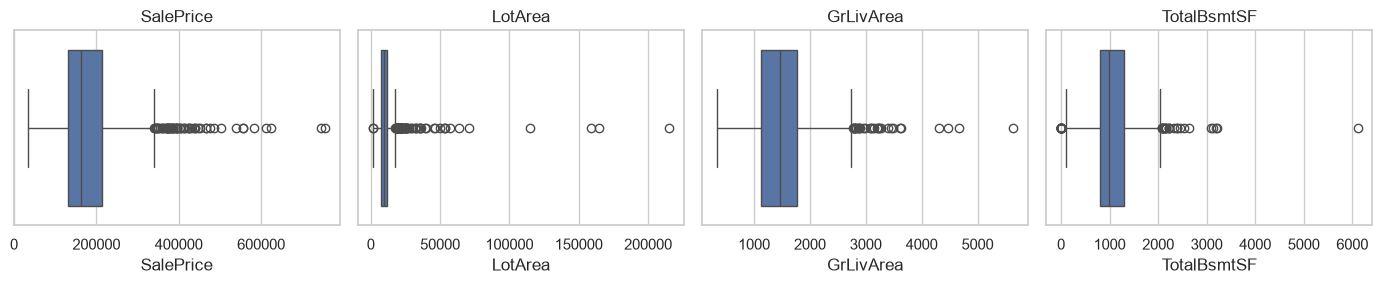

Interpretation: Points beyond the whiskers are unusual under the IQR rule. The chart helps identify values worth checking, but unusually large homes or sale prices can be real, so the records are kept.


In [33]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, column in zip(axes, check_columns):
    sns.boxplot(x=data[column], ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()
print('Interpretation: Points beyond the whiskers are unusual under the IQR rule. The chart helps identify values worth checking, but unusually large homes or sale prices can be real, so the records are kept.')


## 7. Create a few helpful features

We combine related measurements into total indoor area, total bathrooms, outdoor area, and the home's age at sale. These simple features may help the models summarize property size and age. We use the sale year because it is available when a home is sold.

In [34]:
def add_features(frame):
    result = frame.copy()
    result['TotalIndoorSF'] = result[['TotalBsmtSF','1stFlrSF','2ndFlrSF']].fillna(0).sum(axis=1)
    result['TotalBathrooms'] = (result['FullBath'].fillna(0) + .5*result['HalfBath'].fillna(0) +
                                result['BsmtFullBath'].fillna(0) + .5*result['BsmtHalfBath'].fillna(0))
    porch_columns = ['WoodDeckSF','OpenPorchSF','EnclosedPorch','3SsnPorch','ScreenPorch']
    result['OutdoorAreaSF'] = result[porch_columns].fillna(0).sum(axis=1)
    result['AgeAtSale'] = result['YrSold'] - result['YearBuilt']
    result['YearsSinceRemodel'] = result['YrSold'] - result['YearRemodAdd']
    # This is a category code, not a measurement, so treat it as text.
    result['MSSubClass'] = result['MSSubClass'].astype(str)
    return result.drop(columns=['Id','SalePrice'], errors='ignore')

X = add_features(data)
y = data['SalePrice']


## 8. Split the data and prepare model inputs

We use 80% of the rows for training and 20% for the final test. Numeric missing values are filled with the training median and scaled. Text missing values are filled with the most common training value and converted into indicator columns. These steps are kept in a pipeline so cross-validation does not learn from validation rows.

In [35]:
# Group sale prices into bands so both sets contain a spread of price levels.
price_bands = pd.qcut(y, q=10, labels=False, duplicates='drop')
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=price_bands
)

numeric_columns = X_train.select_dtypes(include='number').columns.tolist()
categorical_columns = X_train.select_dtypes(exclude='number').columns.tolist()

try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=True)
except TypeError:  # for older scikit-learn versions
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=True)

numeric_steps = Pipeline([
    ('fill_missing', SimpleImputer(strategy='median', add_indicator=True)),
    ('scale', StandardScaler())
])
category_steps = Pipeline([
    ('fill_missing', SimpleImputer(strategy='most_frequent')),
    ('one_hot', encoder)
])
preparation = ColumnTransformer([
    ('numbers', numeric_steps, numeric_columns),
    ('categories', category_steps, categorical_columns)
])
print(f'Training rows: {len(X_train)} | Test rows: {len(X_test)}')
print(f'Numeric features: {len(numeric_columns)} | Categorical features: {len(categorical_columns)}')


Training rows: 1168 | Test rows: 292
Numeric features: 40 | Categorical features: 44


## 9. Compare regression models

We compare Linear Regression, Ridge Regression, Random Forest, and Gradient Boosting. Five-fold cross-validation splits only the training data into smaller training and validation groups. We compare average RMSE: a lower value means predictions are closer to actual prices, with large errors getting extra penalty.

In [36]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=10),
    'Random Forest': RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE)
}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    model_pipeline = Pipeline([('prepare', preparation), ('model', model)])
    scores = cross_val_score(model_pipeline, X_train, y_train, cv=cv,
                             scoring='neg_root_mean_squared_error', n_jobs=1)
    cv_rows.append({'Model':name, 'Average CV RMSE (USD)':-scores.mean(), 'Fold variation (USD)':scores.std()})
cv_results = pd.DataFrame(cv_rows).sort_values('Average CV RMSE (USD)')
display(cv_results.round(0))


,Model,Average CV RMSE (USD),Fold variation (USD)
3,Gradient Boosting,26470.0,3121.0
2,Random Forest,30693.0,2499.0
1,Ridge Regression,33915.0,7190.0
0,Linear Regression,50791.0,35956.0


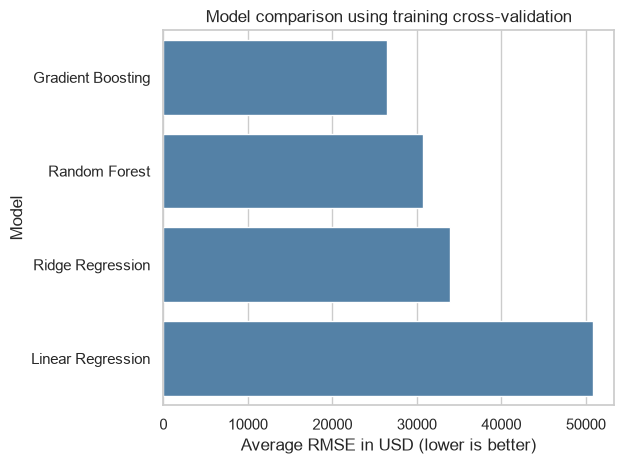

Interpretation: Gradient Boosting has the lowest average cross-validation RMSE in this run. Fold variation shows how much the score changed between the five training splits.


In [37]:
sns.barplot(data=cv_results, x='Average CV RMSE (USD)', y='Model', color='steelblue')
plt.title('Model comparison using training cross-validation')
plt.xlabel('Average RMSE in USD (lower is better)')
plt.tight_layout()
plt.show()
best_cv_model = cv_results.iloc[0]['Model']
print(f"Interpretation: {best_cv_model} has the lowest average cross-validation RMSE in this run. Fold variation shows how much the score changed between the five training splits.")


## 10. Tune the Random Forest

A grid search tries a small set of tree settings and selects the one with the best cross-validation RMSE. This is a simple, systematic tuning step. It uses the training rows only; the test set is still untouched.

In [38]:
forest_pipeline = Pipeline([
    ('prepare', preparation),
    ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
])
parameter_grid = {
    'model__n_estimators':[100, 200],
    'model__max_depth':[None, 15],
    'model__min_samples_leaf':[1, 3]
}
search = GridSearchCV(forest_pipeline, parameter_grid, cv=cv,
                      scoring='neg_root_mean_squared_error', n_jobs=-1)
search.fit(X_train, y_train)
print('Best settings:', search.best_params_)
print(f'Best cross-validation RMSE: {-search.best_score_:,.0f} USD')


Best settings: {'model__max_depth': 15, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best cross-validation RMSE: 30,347 USD


## 11. Final test results

We compare the tuned Random Forest with the strongest model from the earlier cross-validation table. MAE describes the average absolute dollar error, RMSE gives more weight to large errors, and R² describes how much price variation the model explains. RMSLE is also shown because all actual prices are nonnegative; predictions below zero are clipped to zero for RMSLE only.

In [39]:
other_name = cv_results.iloc[0]['Model']
other_model = models[other_name]
other_pipeline = Pipeline([('prepare', preparation), ('model', other_model)])
other_pipeline.fit(X_train, y_train)

final_models = {
    f'Tuned Random Forest': search.best_estimator_,
    f'Best CV model ({other_name})': other_pipeline
}
results = []
predictions = {}
for name, fitted_model in final_models.items():
    predicted = fitted_model.predict(X_test)
    predictions[name] = predicted
    rmsle = np.sqrt(np.mean((np.log1p(y_test) - np.log1p(np.maximum(predicted, 0)))**2))
    results.append({
        'Model':name,
        'MAE (USD)':mean_absolute_error(y_test, predicted),
        'RMSE (USD)':mean_squared_error(y_test, predicted)**0.5,
        'R2':r2_score(y_test, predicted),
        'RMSLE':rmsle
    })
test_results = pd.DataFrame(results).sort_values('RMSE (USD)')
display(test_results.round(3))


,Model,MAE (USD),RMSE (USD),R2,RMSLE
1,Best CV model (Gradient Boosting),15046.405,23245.362,0.916,0.122
0,Tuned Random Forest,14904.835,23929.417,0.911,0.128


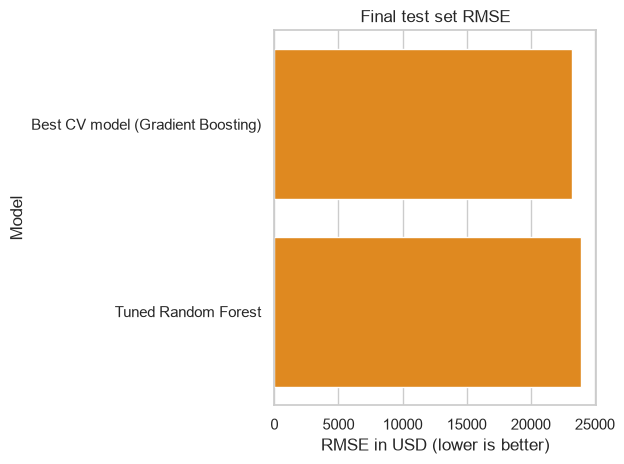

Interpretation: Best CV model (Gradient Boosting) performed best by test RMSE. Its MAE is $15,046, so the typical absolute prediction error is about this size in this test sample. R2 is 0.916.


In [40]:
sns.barplot(data=test_results, x='RMSE (USD)', y='Model', color='darkorange')
plt.title('Final test set RMSE')
plt.xlabel('RMSE in USD (lower is better)')
plt.tight_layout()
plt.show()
chosen_name = test_results.iloc[0]['Model']
chosen_prediction = predictions[chosen_name]
best = test_results.iloc[0]
print(f"Interpretation: {chosen_name} performed best by test RMSE. Its MAE is ${best['MAE (USD)']:,.0f}, so the typical absolute prediction error is about this size in this test sample. R2 is {best['R2']:.3f}.")


## 12. Review prediction errors

A residual is actual price minus predicted price. Positive residuals mean the model predicted too low; negative residuals mean it predicted too high. These charts help show whether errors are centered around zero and whether errors change for more expensive homes.

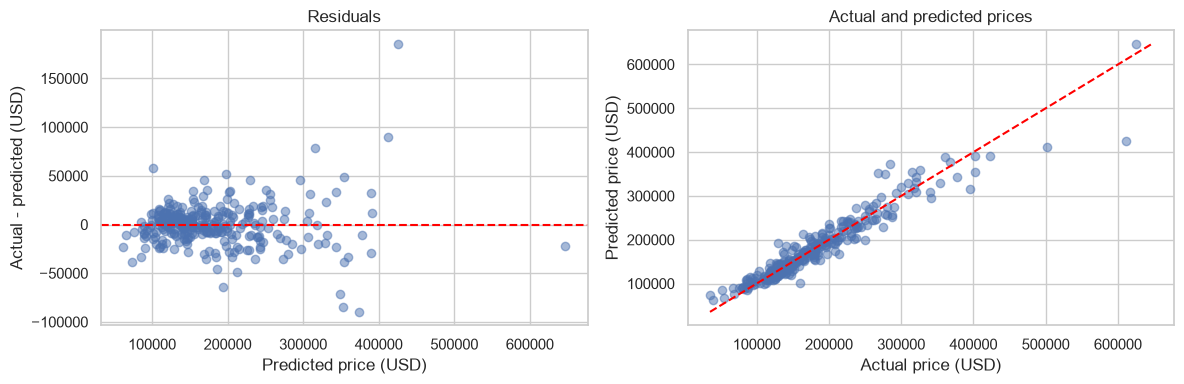

Interpretation: Average residual is $-253. In the first chart, a pattern or widening spread can show where the model struggles. In the second, points close to the red line have more accurate predictions.


In [41]:
residuals = y_test.to_numpy() - chosen_prediction
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(chosen_prediction, residuals, alpha=.5)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set(xlabel='Predicted price (USD)', ylabel='Actual - predicted (USD)', title='Residuals')
axes[1].scatter(y_test, chosen_prediction, alpha=.5)
low = min(y_test.min(), chosen_prediction.min())
high = max(y_test.max(), chosen_prediction.max())
axes[1].plot([low, high], [low, high], color='red', linestyle='--')
axes[1].set(xlabel='Actual price (USD)', ylabel='Predicted price (USD)', title='Actual and predicted prices')
plt.tight_layout()
plt.show()
print(f"Interpretation: Average residual is ${residuals.mean():,.0f}. In the first chart, a pattern or widening spread can show where the model struggles. In the second, points close to the red line have more accurate predictions.")


## 13. Which features helped the model?

Permutation importance measures how much the test score changes when the values of one feature are shuffled. It gives a simple view of which inputs the selected model used most. This is an association with prediction accuracy, not proof that changing the feature changes a home's price.

,Feature,Importance
79,TotalIndoorSF,0.305436
16,OverallQual,0.149678
60,GarageCars,0.017945
80,TotalBathrooms,0.016334
43,2ndFlrSF,0.016016
3,LotArea,0.009932
11,Neighborhood,0.006783
29,BsmtQual,0.006408
17,OverallCond,0.005616
58,GarageYrBlt,0.005499


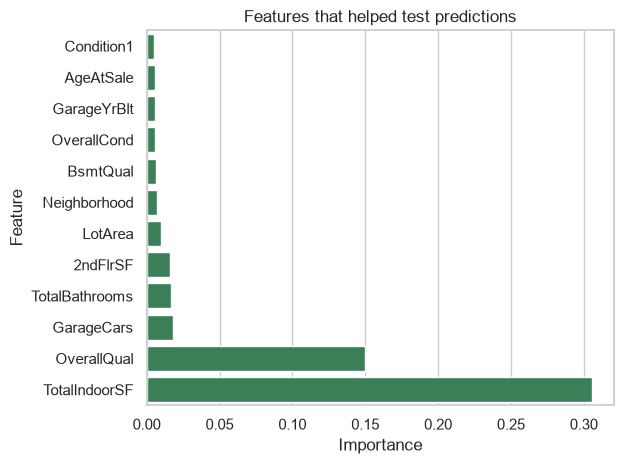

Interpretation: Features at the top had the largest average effect on the model score when shuffled. Similar or related features can share importance.


In [42]:
chosen_model = final_models[chosen_name]
importance_result = permutation_importance(chosen_model, X_test, y_test,
                                           n_repeats=5, random_state=RANDOM_STATE,
                                           scoring='r2', n_jobs=-1)
importance = pd.DataFrame({
    'Feature':X_test.columns,
    'Importance':importance_result.importances_mean
}).sort_values('Importance', ascending=False).head(12)
display(importance)
sns.barplot(data=importance.sort_values('Importance'), x='Importance', y='Feature', color='seagreen')
plt.title('Features that helped test predictions')
plt.tight_layout()
plt.show()
print('Interpretation: Features at the top had the largest average effect on the model score when shuffled. Similar or related features can share importance.')


## 14. Model comparison report

The comparison below puts cross-validation and final test results together. The test set is the main estimate of performance for this project. The model with the lowest score here is the best choice for this split, but a new test sample could produce a different ranking.

In [43]:

# Model comparison report: combine CV and test results correctly

cv_lookup = cv_results.set_index('Model').to_dict('index')

report_rows = []

for _, row in test_results.iterrows():
    model_name = row['Model']

    if model_name == 'Tuned Random Forest':
        cv_rmse = -search.best_score_
        cv_std = search.cv_results_['std_test_score'][search.best_index_]

    elif model_name.startswith('Best CV model ('):
        original_name = model_name.replace('Best CV model (', '').replace(')', '')
        cv_rmse = cv_lookup[original_name]['Average CV RMSE (USD)']
        cv_std = cv_lookup[original_name]['Fold variation (USD)']

    report_rows.append({
        'Model': model_name,
        'CV RMSE (USD)': cv_rmse,
        'CV Fold Variation (USD)': cv_std,
        'Test MAE (USD)': row['MAE (USD)'],
        'Test RMSE (USD)': row['RMSE (USD)'],
        'Test R2': row['R2'],
        'Test RMSLE': row['RMSLE']
    })

report = pd.DataFrame(report_rows).sort_values('Test RMSE (USD)')

display(report.round(3))

print(
    f"Best model based on test RMSE: "
    f"{report.iloc[0]['Model']}"
)


,Model,CV RMSE (USD),CV Fold Variation (USD),Test MAE (USD),Test RMSE (USD),Test R2,Test RMSLE
0,Best CV model (Gradient Boosting),26469.786,3121.068,15046.405,23245.362,0.916,0.122
1,Tuned Random Forest,30347.140,2362.047,14904.835,23929.417,0.911,0.128


Best model based on test RMSE: Best CV model (Gradient Boosting)


## 15. Simple customer recommendations

The table below searches historical sales that match a customer's budget, minimum living area, and optional neighborhood/bedroom needs. It can show model estimates for those records. These are examples in the dataset, not current listings or professional valuations.

In [44]:
# Change these example preferences to explore the dataset.
customer_budget = 200000
minimum_area = 1200
preferred_neighborhood = None  # Example: 'NridgHt'; None means any neighborhood
minimum_bedrooms = 3

recommendations = data[(data['SalePrice'] <= customer_budget) &
                       (data['GrLivArea'] >= minimum_area)].copy()
if preferred_neighborhood is not None:
    recommendations = recommendations[recommendations['Neighborhood'] == preferred_neighborhood]
if minimum_bedrooms is not None:
    recommendations = recommendations[recommendations['BedroomAbvGr'] >= minimum_bedrooms]
recommendations['Area difference'] = (recommendations['GrLivArea'] - minimum_area).abs()
recommendations = recommendations.sort_values(['Area difference','SalePrice']).head(10)
if recommendations.empty:
    print('No historical homes match. Try changing the budget or requirements.')
else:
    model_estimate = np.maximum(chosen_model.predict(add_features(recommendations)), 0)
    recommendations['Model estimate (USD)'] = model_estimate.round(0).astype(int)
    show_columns = ['Id','Neighborhood','SalePrice','Model estimate (USD)','GrLivArea','OverallQual','BedroomAbvGr','YearBuilt']
    display(recommendations[show_columns].reset_index(drop=True))
    print(f"Interpretation: {len(recommendations)} past sales match the chosen filters. The model estimate is an educational comparison to the recorded sale price; it does not show that a home is currently for sale.")


,Id,Neighborhood,SalePrice,Model estimate (USD),GrLivArea,OverallQual,BedroomAbvGr,YearBuilt
0,155,OldTown,125000,113351,1200,6,4,1923
1,840,Edwards,130500,119333,1200,5,3,1946
2,356,CollgCr,177500,172305,1200,6,3,1995
3,739,Edwards,179000,155881,1200,5,3,1987
4,460,BrkSide,110000,115130,1203,5,3,1950
5,673,Veenker,165000,170368,1208,6,3,1977
6,1222,Sawyer,134000,127347,1211,5,3,1968
7,263,Sawyer,151000,153822,1212,6,3,1977
8,1199,CollgCr,178000,170772,1212,7,3,2001
9,212,Edwards,186000,174024,1212,6,3,2009


Interpretation: 10 past sales match the chosen filters. The model estimate is an educational comparison to the recorded sale price; it does not show that a home is currently for sale.


## 16. Challenges and what I did

- **Only one labelled file was supplied:** split the available records into training and test sets.
- **Some blanks mean a feature is absent:** coded known structural absences as `None` or zero. Other blanks are treated as unknown and filled during model training.
- **Many columns are categories:** converted categories into indicator columns inside a pipeline.
- **Some homes have unusual sizes or prices:** flagged them with the IQR rule and kept them because they can be real examples.
- **Different models perform differently:** used five-fold cross-validation, then tuned a small Random Forest grid.
- **Results are from Ames historical sales:** performance may not transfer to other locations or current prices.
- **Recommendations use historical data:** the notebook cannot check current inventory or the condition of a property.


## 17. Conclusion

## Conclusion

The House Price Prediction project successfully developed machine learning models to estimate residential property prices using various housing features from the Ames Housing dataset. Data preprocessing, exploratory data analysis, feature engineering, and model evaluation were performed to improve prediction performance.

Four regression algorithms were evaluated: Linear Regression, Ridge Regression, Random Forest, and Gradient Boosting. After comparing their performance through cross-validation and test evaluation, **Gradient Boosting was selected as the best-performing model**, achieving an RMSE of approximately **$23,245**, an MAE of **$15,046**, and an R² score of **0.916** on the test dataset.

The results demonstrate that machine learning can effectively identify patterns in housing data and provide accurate price estimates. This project also highlights the importance of data preprocessing, model comparison, and hyperparameter tuning in building reliable predictive models. The developed model can serve as a foundation for future improvements, such as incorporating more recent housing data and developing a user-friendly house price prediction application.